<a href="https://colab.research.google.com/github/fifanuurunhalizah09/PCVK_Ganjil2026/blob/main/Week8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS INDIVIDU**

In [ ]:
# 1. Buat file baru di Google Colab, rename menjadi "Week7.ipynb"
# 2. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

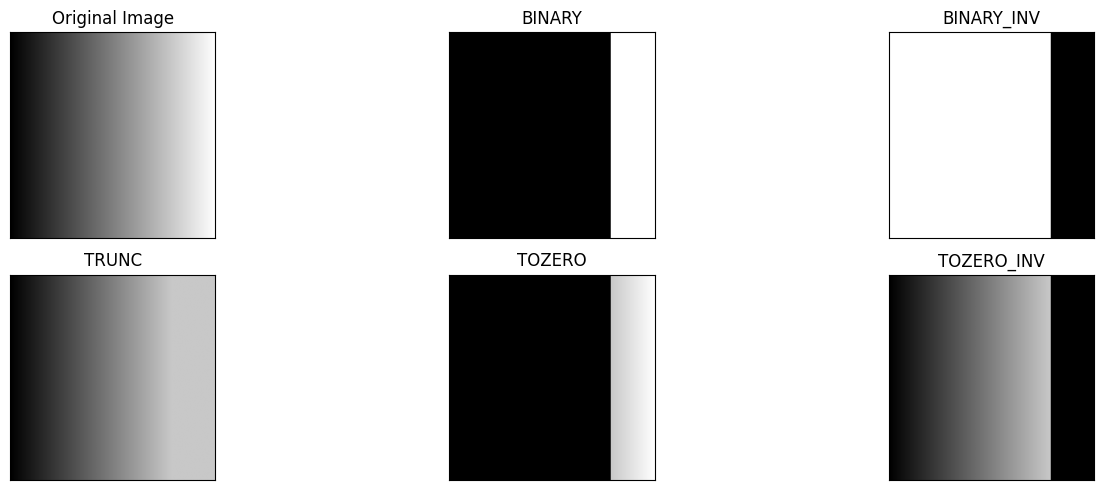

In [ ]:
# Buat citra gradien sederhana (atau gunakan citra Anda)
# Misalnya: gradient.jpg
filename = '/content/drive/MyDrive/PCVK/Images/gradient.jpg'
img = cv.imread(filename, 0)  # baca sebagai grayscale

# Jika tidak ada file, buat citra gradien sintetis
if img is None:
    img = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (256, 1))

thresh = 200
maxval = 255

# 1. BINARY
# Jika piksel > thresh -> maxval, else 0
binary = np.where(img > thresh, maxval, 0).astype(np.uint8)

# 2. BINARY_INV
# Jika piksel > thresh -> 0, else maxval
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)

# 3. TRUNC
# Jika piksel > thresh -> thresh, else tetap
trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. TOZERO
# Jika piksel > thresh -> tetap, else 0
tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. TOZERO_INV
# Jika piksel > thresh -> 0, else tetap
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

# Tampilkan hasil
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

Memproses Adaptive Mean...
Memproses Adaptive Gaussian...


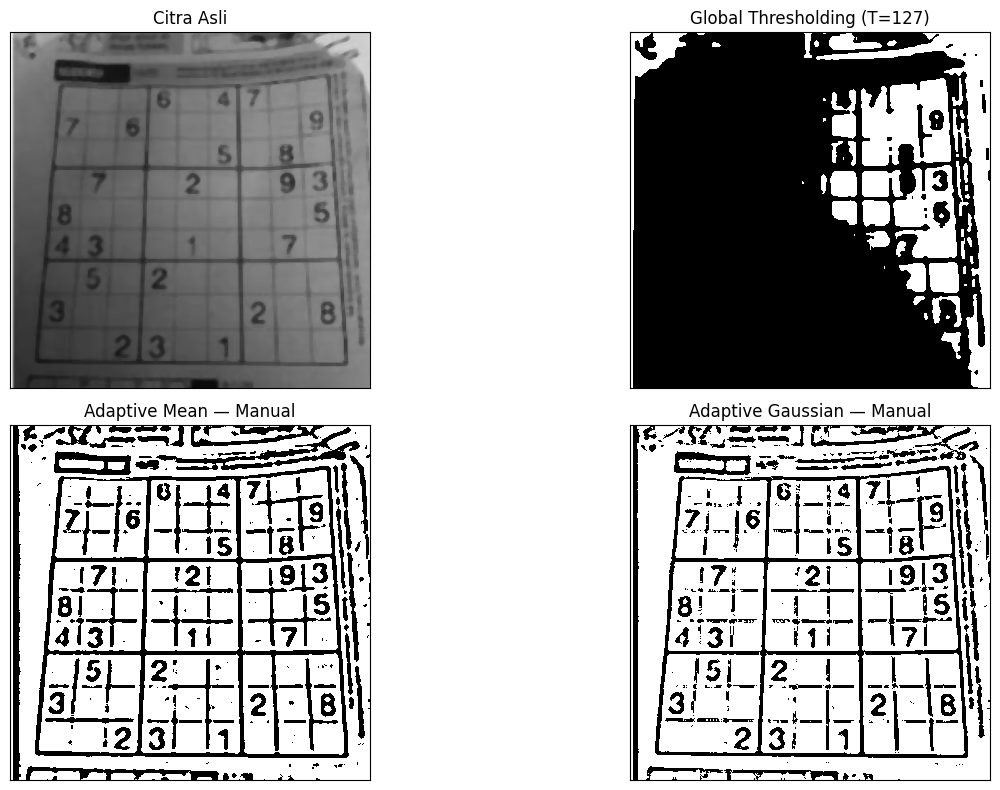

In [ ]:
# Baca citra sudoku
filename = '/content/drive/MyDrive/PCVK 2026/sudoku-original.png'
citra = cv.imread(filename)
citra = cv.medianBlur(citra, 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

# Global threshold manual dengan ambang 127
global_thresh = np.where(gray > 127, 255, 0).astype(np.uint8)

# Fungsi Adaptive Mean Threshold manual
def adaptive_mean_manual(gray, block_size=11, C=2):
    """
    Adaptive threshold dengan rata-rata lokal.
    block_size harus ganjil.
    """
    h, w = gray.shape
    pad = block_size // 2
    # Padding citra agar tepi tetap terproses
    padded = np.pad(gray, pad, mode='reflect')
    result = np.zeros_like(gray, dtype=np.uint8)

    for i in range(h):
        for j in range(w):
            # Ambil window block_size x block_size
            window = padded[i:i+block_size, j:j+block_size]
            mean = np.mean(window)
            threshold = mean - C
            if gray[i, j] > threshold:
                result[i, j] = 255
            else:
                result[i, j] = 0
    return result

# Fungsi Adaptive Gaussian Threshold manual
def adaptive_gaussian_manual(gray, block_size=11, C=2, sigma=2):
    """
    Adaptive threshold dengan rata-rata Gaussian lokal.
    """
    h, w = gray.shape
    pad = block_size // 2
    padded = np.pad(gray, pad, mode='reflect')
    result = np.zeros_like(gray, dtype=np.uint8)

    # Buat kernel Gaussian 2D
    ax = np.arange(-pad, pad + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel = kernel / np.sum(kernel)

    for i in range(h):
        for j in range(w):
            window = padded[i:i+block_size, j:j+block_size]
            # Rata-rata Gaussian = konvolusi window dengan kernel
            gaussian_mean = np.sum(window * kernel)
            threshold = gaussian_mean - C
            if gray[i, j] > threshold:
                result[i, j] = 255
            else:
                result[i, j] = 0
    return result

# Jalankan (proses ini lambat karena loop per piksel)
print("Memproses Adaptive Mean...")
adaptive_mean = adaptive_mean_manual(gray, block_size=11, C=2)

print("Memproses Adaptive Gaussian...")
adaptive_gaussian = adaptive_gaussian_manual(gray, block_size=11, C=2, sigma=2)

# Tampilkan hasil
titles = ['Citra Asli', 'Global Thresholding (T=127)', 'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
images = [gray, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(15, 8))
for i in range(len(images)):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

/tmp/ipykernel_1959/1139466022.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
/tmp/ipykernel_1959/1139466022.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)


93


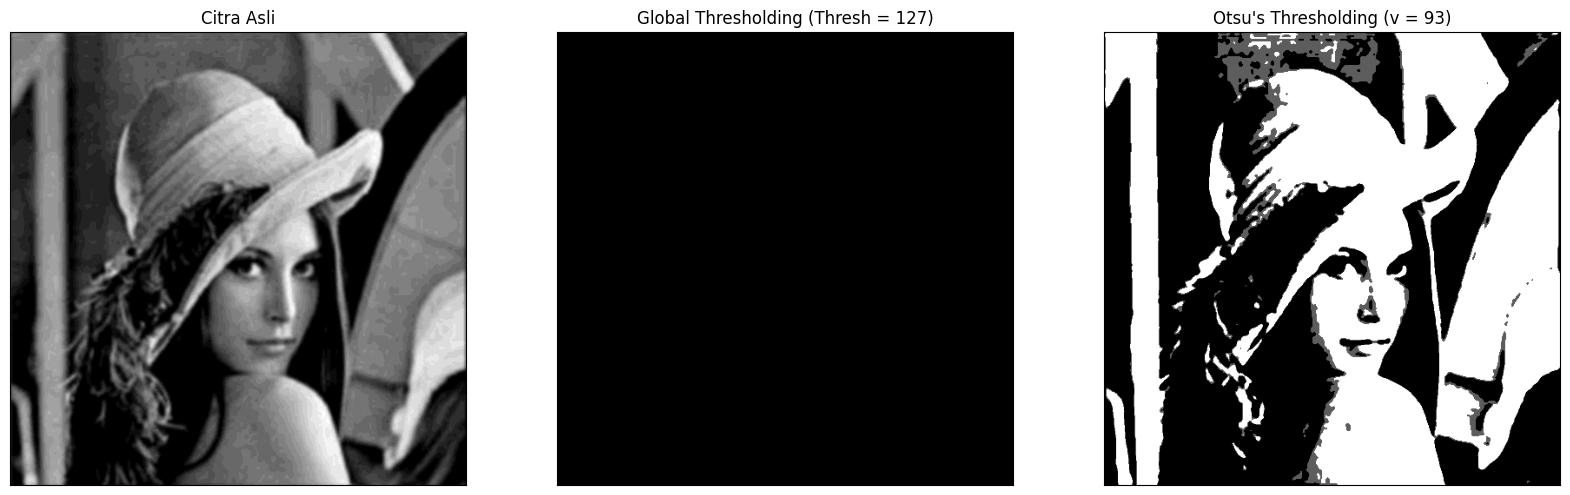

In [ ]:
filename = '/content/drive/MyDrive/PCVK 2026/lena_gs_lc2_fixed.png'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = " + str(otsu_thresh) + ")")
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli',
          'Global Thresholding (Thresh = ' + str(thresh) + ')',
          x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

KTP dimuat: (458, 694)
Min: 0 | Max: 255
166


/tmp/ipykernel_1959/1139466022.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)


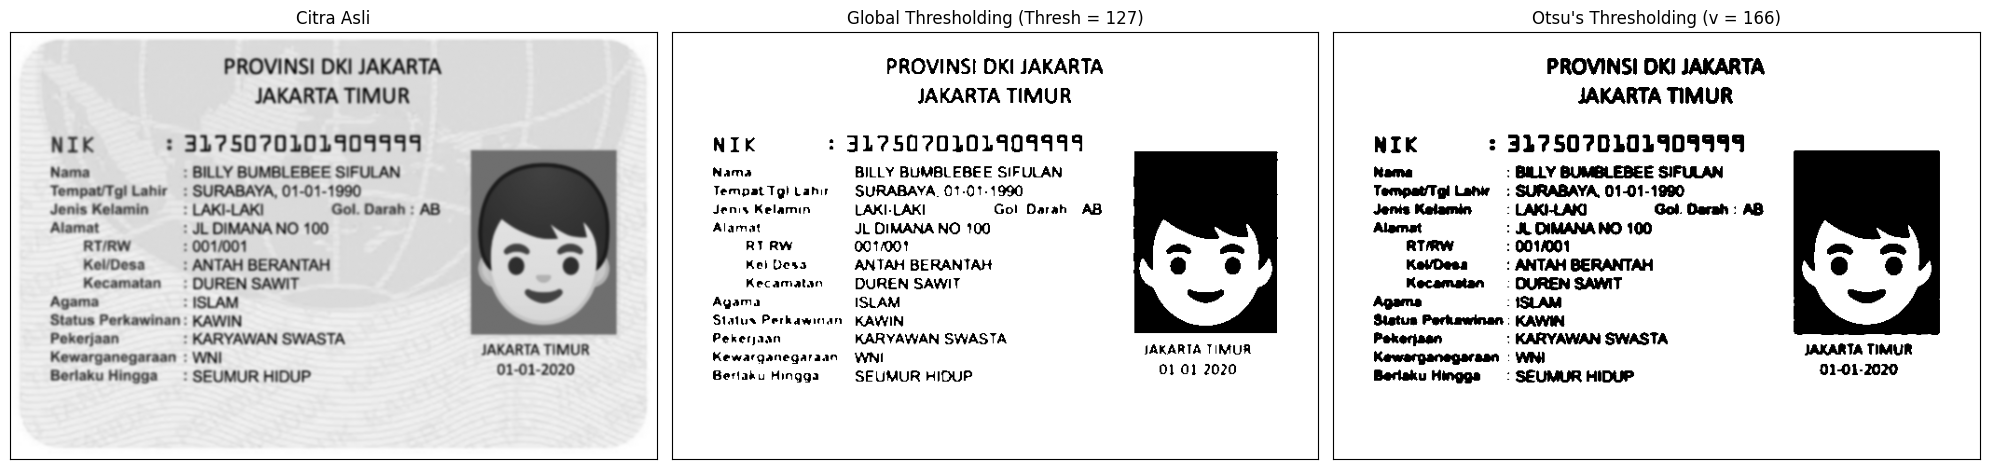

In [ ]:
filename_ktp = '/content/drive/MyDrive/PCVK 2026/ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp, 0)

if img_ktp is None:
    print("File KTP tidak ditemukan. Cek nama & ekstensinya!")
    import os
    folder = os.path.dirname(filename_ktp)
    for f in os.listdir(folder):
        if 'ktp' in f.lower():
            print(" -", f)
else:
    print("KTP dimuat:", img_ktp.shape)
    print("Min:", img_ktp.min(), "| Max:", img_ktp.max())

    blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)
    thresh = 127

    # Pakai fungsi otsu() yang sudah dibuat sebelumnya
    otsu_ktp_biner, otsu_ktp_thresh = otsu(blur_ktp)

    # Global threshold T=127
    _, global_ktp = cv.threshold(blur_ktp, thresh, 255, cv.THRESH_BINARY)

    # Tampilkan
    titles = ['Citra Asli',
              f'Global Thresholding (Thresh = {thresh})',
              f"Otsu's Thresholding (v = {otsu_ktp_thresh})"]
    citra_ktp = [blur_ktp, global_ktp, otsu_ktp_biner]

    plt.figure(figsize=(20, 8))
    for i in range(len(citra_ktp)):
        plt.subplot(1, 3, i + 1)
        plt.imshow(citra_ktp[i], 'gray', vmin=0, vmax=255)
        plt.title(titles[i])
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()

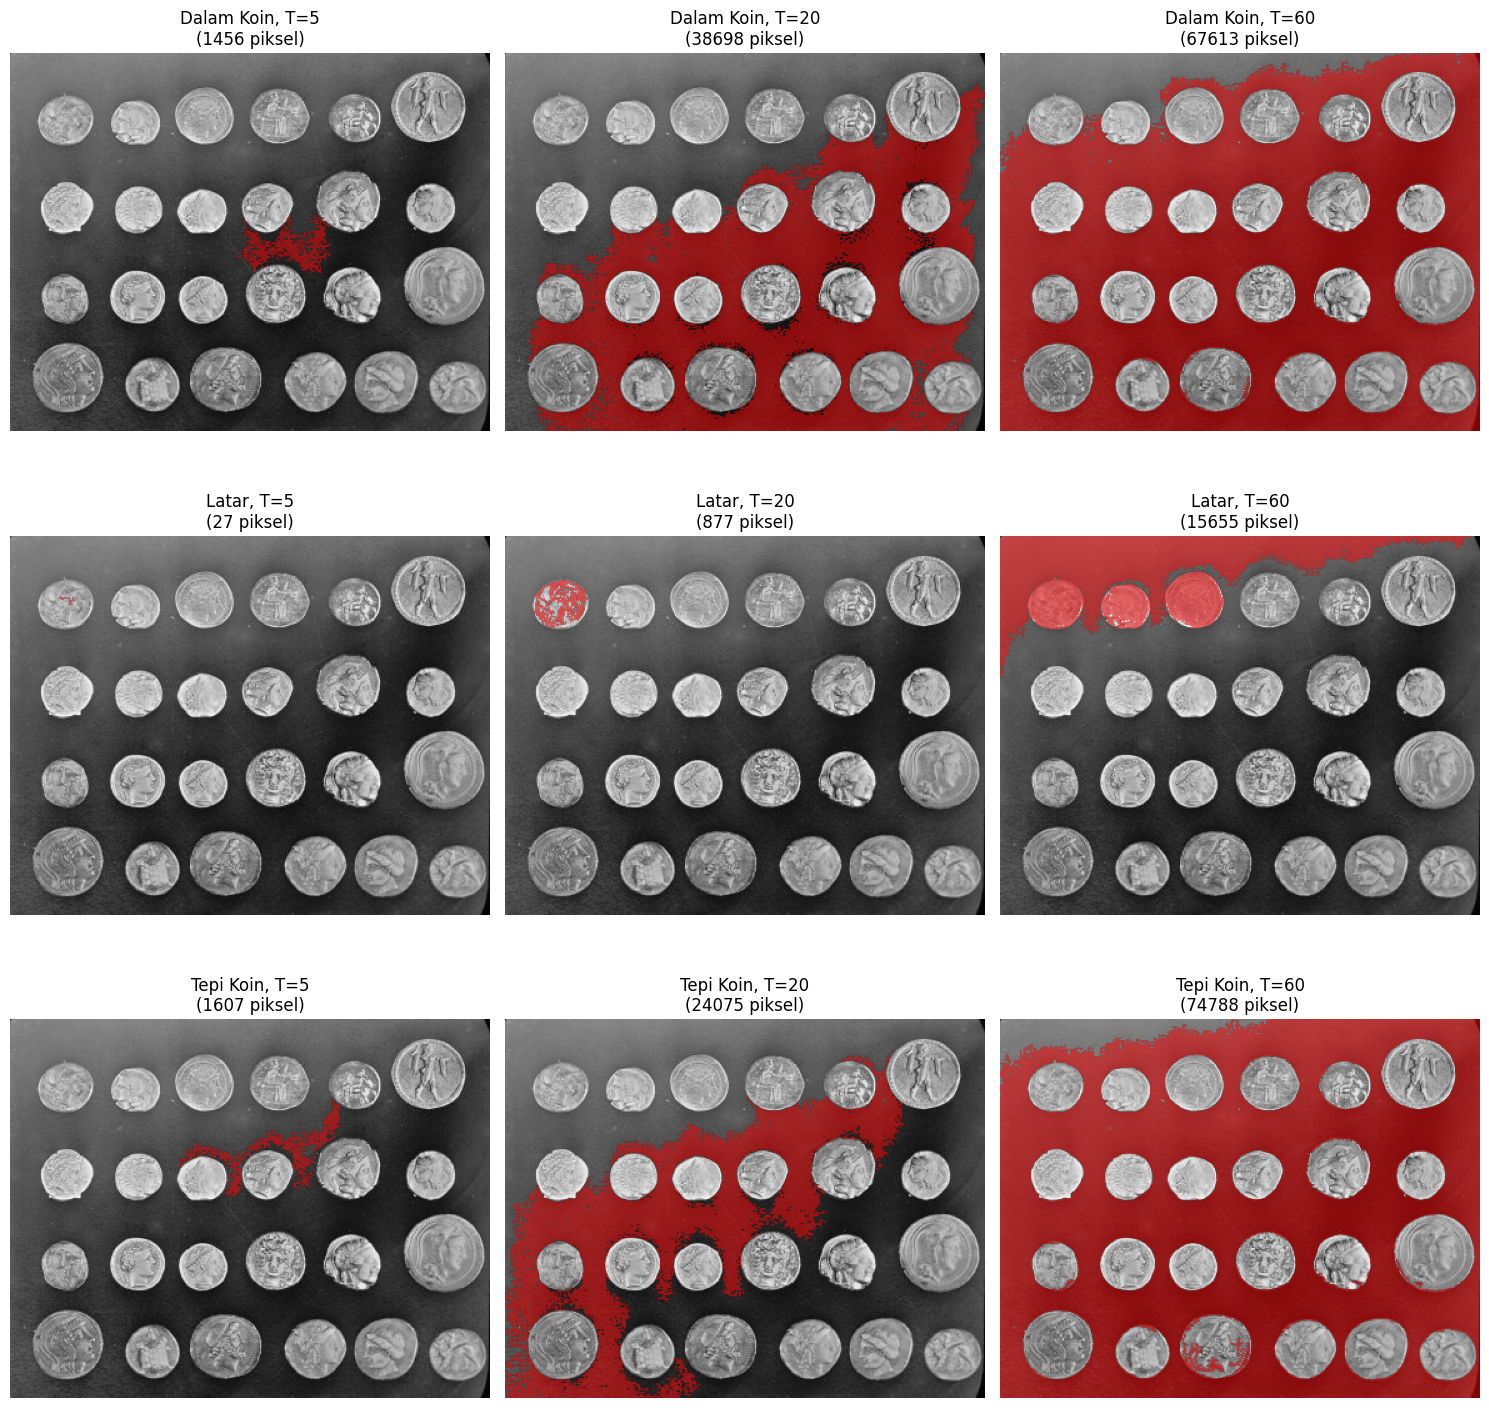

In [ ]:
from skimage import data
from collections import deque
import numpy as np
import matplotlib.pyplot as plt

img_coins = data.coins()

def region_growing(img, seed, T):
    """
    Region growing manual dengan 4-ketetanggaan.
    """
    h, w = img.shape
    visited = np.zeros((h, w), dtype=bool)
    region = np.zeros((h, w), dtype=bool)

    seed_val = img[seed]
    queue = deque([seed])
    visited[seed] = True
    region[seed] = True

    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while queue:
        x, y = queue.popleft()
        for dx, dy in neighbors:
            nx, ny = x + dx, y + dy
            if 0 <= nx < h and 0 <= ny < w and not visited[nx, ny]:
                visited[nx, ny] = True
                if abs(int(img[nx, ny]) - int(seed_val)) <= T:
                    region[nx, ny] = True
                    queue.append((nx, ny))
    return region

# 3 seed (sesuaikan kalau perlu)
seeds = {
    'Dalam Koin': (150, 200),
    'Latar':      (50, 50),
    'Tepi Koin':  (120, 180),
}
T_values = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for i, (seed_name, seed) in enumerate(seeds.items()):
    for j, T in enumerate(T_values):
        mask = region_growing(img_coins, seed, T)
        ax = axes[i, j]
        ax.imshow(img_coins, cmap='gray')
        overlay = np.zeros((*img_coins.shape, 4))
        overlay[mask] = [1, 0, 0, 0.5]
        ax.imshow(overlay)
        ax.set_title(f'{seed_name}, T={T}\n({np.sum(mask)} piksel)')
        ax.axis('off')
plt.tight_layout()
plt.show()

Shape: (303, 384)
Versi skimage: 0.25.2

Seed terpilih: (55, 98) | intensitas: 183
Toleransi   5:     39 piksel
Toleransi  20:    728 piksel
Toleransi  60:   1116 piksel


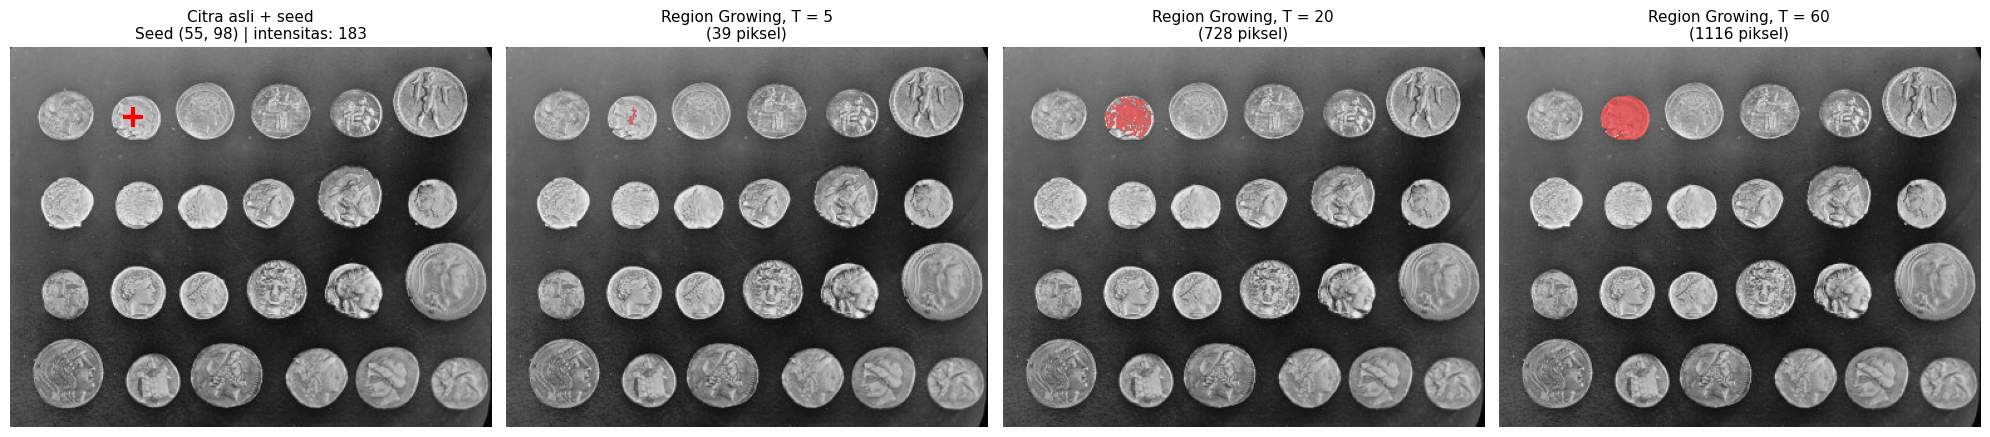

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()
print(f"Shape: {gray.shape}")
print(f"Versi skimage: {__import__('skimage').__version__}")

def cari_seed_optimal(img):
    """Cari piksel di tengah koin: intensitas sedang & homogen."""
    best_seed, best_score = None, -1
    h, w = img.shape
    for r in range(30, h - 30):
        for c in range(30, w - 30):
            val = int(img[r, c])
            if not (150 <= val <= 185):
                continue
            tetangga = [img[r-5, c], img[r+5, c], img[r, c-5], img[r, c+5],
                        img[r-5, c-5], img[r-5, c+5], img[r+5, c-5], img[r+5, c+5]]
            max_diff = max(abs(val - int(t)) for t in tetangga)
            if max_diff < 20:
                score = val - max_diff
                if score > best_score:
                    best_score = score
                    best_seed = (r, c)
    return best_seed

# Pakai seed otomatis
seed = cari_seed_optimal(gray)

print(f"\nSeed terpilih: {seed} | intensitas: {gray[seed]}")
tolerances = [5, 20, 60]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Panel 1: Citra asli + seed
axes[0].imshow(gray, cmap='gray')
axes[0].plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
axes[0].set_title(f'Citra asli + seed\nSeed {seed} | intensitas: {gray[seed]}',
                  fontsize=11)
axes[0].axis('off')

# Panel 2-4: flood() untuk setiap toleransi
for k, tol in enumerate(tolerances, start=1):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=tol,
        connectivity=1   # 4 tetangga untuk citra 2D
    )
    n_pixels = int(np.sum(region))
    print(f"Toleransi {tol:3d}: {n_pixels:6d} piksel")

    axes[k].imshow(gray, cmap='gray')
    overlay = np.zeros((*gray.shape, 4))
    overlay[region] = [1, 0, 0, 0.5]   # merah transparan
    axes[k].imshow(overlay)
    axes[k].set_title(f'Region Growing, T = {tol}\n({n_pixels} piksel)',
                      fontsize=11)
    axes[k].axis('off')

plt.tight_layout()
plt.show()

Shape citra: (458, 694, 3)
Jumlah piksel biru: 247407


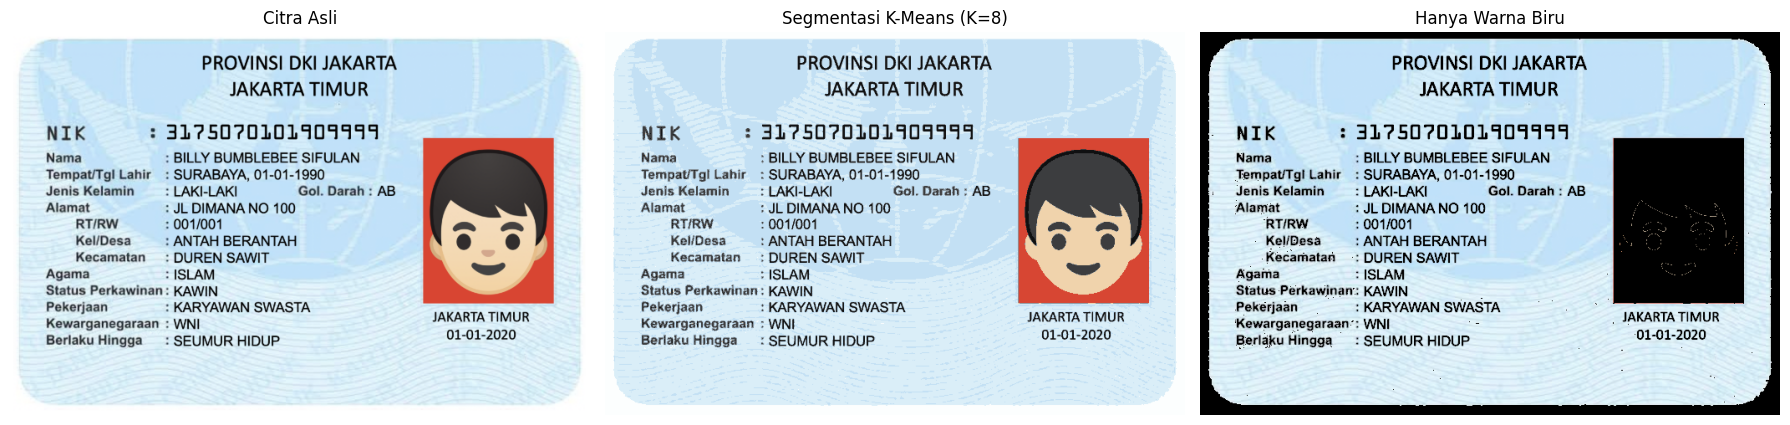

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# ============================================================
# 1. Baca citra KTP
# ============================================================
filename_ktp = '/content/drive/MyDrive/PCVK 2026/ktp_fulan.jpg'

img_bgr = cv.imread(filename_ktp)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

print(f"Shape citra: {img_rgb.shape}")


# ============================================================
# 2. K-Means Clustering (K=8)
# ============================================================
# Reshape ke 2D array: (N_piksel, 3)
Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

# K-Means dengan K=8
k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

# Dapatkan label & pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img_rgb.shape)


# ============================================================
# 3. Filter hanya warna biru (HSV)
# ============================================================
# Konversi hasil segmentasi ke HSV
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]

# Rentang biru (sesuai jobsheet):
# H: 85-130, S: >=25, V: >=40
mask_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

# Citra hanya warna biru (sisanya hitam)
hasil_biru = np.zeros_like(img_rgb)
hasil_biru[mask_biru] = img_rgb[mask_biru]

print(f"Jumlah piksel biru: {np.sum(mask_biru)}")


# ============================================================
# 4. Tampilkan hasil (3 panel)
# ============================================================
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(segmented_img)
plt.title(f'Segmentasi K-Means (K={k})')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_biru)
plt.title('Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()

**TUGAS KELOMPOK**


In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [10]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output

In [18]:
filename_ktp = '/content/drive/MyDrive/PCVK 2026/ktp.png'
img_bgr = cv.imread(filename_ktp)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

print(f"Shape citra: {img_rgb.shape}")

Shape citra: (317, 513, 3)


In [19]:
# Otsu
blur = cv.GaussianBlur(img_gray, (5, 5), 0)
_, otsu_img = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print(f"Otsu threshold: {_}")

# Adaptive
adaptive_img = cv.adaptiveThreshold(
    img_gray, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY, 11, 2
)

Otsu threshold: 115.0


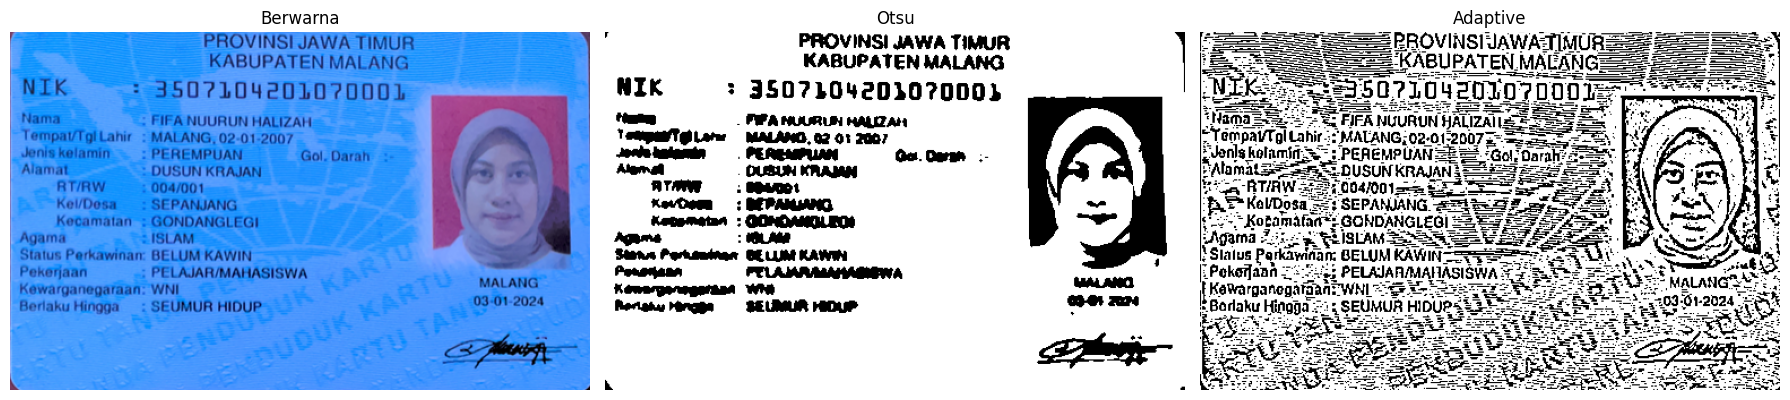

In [20]:
titles = ['Berwarna', 'Otsu', 'Adaptive']
images = [img_rgb, otsu_img, adaptive_img]

plt.figure(figsize=(18, 6))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    if i == 0:
        plt.imshow(images[i])
    else:
        plt.imshow(images[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# Konfigurasi OCR
# ============================================================
config = r'--oem 3 --psm 6 -l ind'

In [22]:
text_berwarna = pytesseract.image_to_string(img_rgb, config=config)
text_otsu     = pytesseract.image_to_string(otsu_img, config=config)
text_adaptive = pytesseract.image_to_string(adaptive_img, config=config)

print("******** BERWARNA ********")
print(text_berwarna)

print("\n******** OTSU ********")
print(text_otsu)

print("\n******** ADAPTIVE ********")
print(text_adaptive)

******** BERWARNA ********
& PROVINSI JAWA TIMUR
KABUPATEN MALANG
NIK 1 350?104201070001
Nama FIFA NUURUN HALIZAH ?
Tempat/Tgi Lahir : MALANG, 02-01:2007
Jenis kelamin - : PEREMPUAN Gol, Darah 4
Alamat DUSUN KRAJAN
RTRW 004001 "
KelDosa : SEPANJANG
| Ketamatan : GONDANGLEGI A
Agama ISLAM
Status Parkawinan: BELUM KAWIN
Pekerjaan PELAJAR/MAHASISWA MALANG
Kewarganegaraan: WNI Aa
Berlaku Hingga: SEUMUR HIDUP:
| »


******** OTSU ********
. PROVINSI JAWA TIMUR
KABUPATEN MALANG
NIK 3 3SO?1042010?0001
— MEA MUAL KALIAN
Tengas/TO Lane MALANG, 52 01 2007
mebkalann —. PERGUPUNA Ga. Dera :-
Mama DUSUN KRAJAN
ATA. B0Mno1 —
KevOsea : BEPAKJANG Kn
Ketamatan : DONDAMULEO
Amma 6
Stan Pertandaan BELUM KAWIN :
#enanaan MELAMAMMABWA mana
tembatea ma
: |


******** ADAPTIVE ********
He Ga —-PROVINSIJAWATTIMUR EA an
Ia oU 2 KABUPATENMALANGE 51
Ba na at
ME 5 A5071OYPUNOOO9 IT ee
Mn abah en anna

(Hama 5528 FIFA NUURUN YALIZAI PA Kn £
ET EMPAVTG Lahir : MALANG: 02-017200727 2x LA KAN Bi
Kbonlaholam TR PEREMP

In [23]:
print("Panjang text_berwarna:", len(text_berwarna))
print("Panjang text_otsu    :", len(text_otsu))
print("Panjang text_adaptive:", len(text_adaptive))

Panjang text_berwarna: 386
Panjang text_otsu    : 307
Panjang text_adaptive: 668


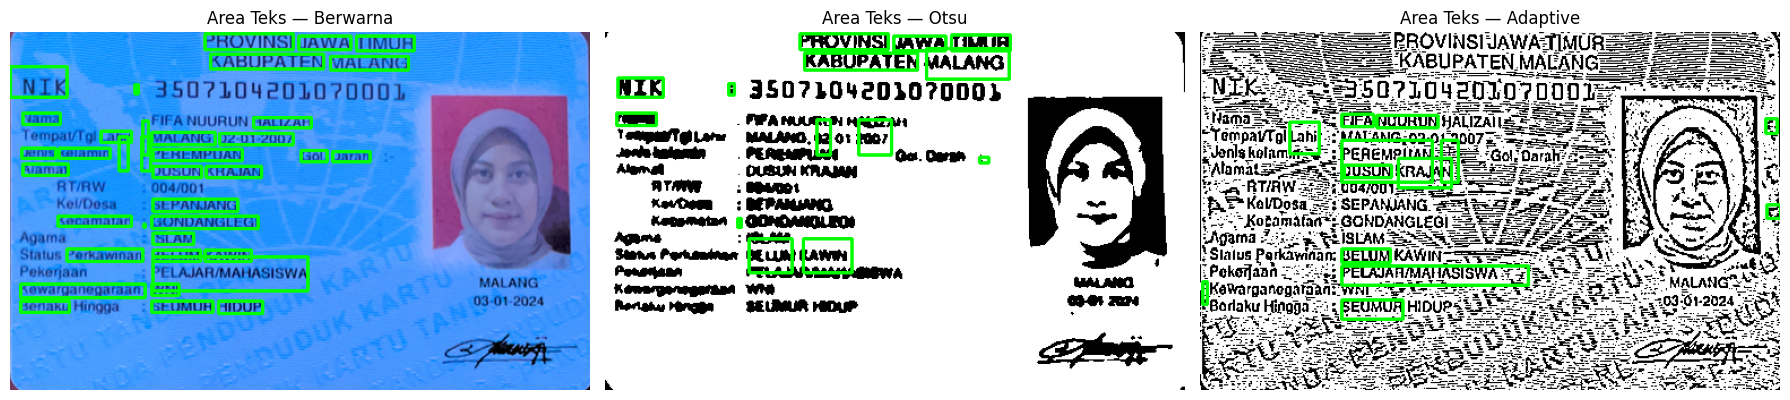

In [24]:
def tampilkan_kotak_teks(img, config, confidence_threshold=60):
    data = pytesseract.image_to_data(img, config=config, output_type=Output.DICT)
    img_copy = img.copy()
    for i in range(len(data['text'])):
        if int(data['conf'][i]) > confidence_threshold:
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(img_copy, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return img_copy

img_berwarna_box = tampilkan_kotak_teks(img_rgb, config)
img_otsu_box     = tampilkan_kotak_teks(cv.cvtColor(otsu_img, cv.COLOR_GRAY2RGB), config)
img_adaptive_box = tampilkan_kotak_teks(cv.cvtColor(adaptive_img, cv.COLOR_GRAY2RGB), config)

plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1); plt.imshow(img_berwarna_box); plt.title('Area Teks — Berwarna'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(img_otsu_box);     plt.title('Area Teks — Otsu');     plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(img_adaptive_box); plt.title('Area Teks — Adaptive'); plt.axis('off')
plt.tight_layout()
plt.show()

In [25]:
acuan = [
    "PROVINSI DKI JAKARTA",
    "JAKARTA TIMUR",
    "NIK",
    "31750701014041419",
    "BILLY BUMBLEBEE SIFULAN",
    "SURABAYA",
    "01-01-1990",
    "LAKI-LAKI",
    "ISLAM",
    "SEUMUR HIDUP"
]

def hitung_kecocokan(acuan, hasil):
    cocok = 0
    detail = []
    for item in acuan:
        if item.lower() in hasil.lower():
            cocok += 1
            detail.append(f"✅ {item}")
        else:
            detail.append(f"❌ {item}")
    return cocok, (cocok / len(acuan)) * 100, detail

cocok_b, persen_b, detail_b = hitung_kecocokan(acuan, text_berwarna)
cocok_o, persen_o, detail_o = hitung_kecocokan(acuan, text_otsu)
cocok_a, persen_a, detail_a = hitung_kecocokan(acuan, text_adaptive)

print("=" * 40)
print("RINGKASAN KECOCOKAN")
print("=" * 40)
print(f"Berwarna : {cocok_b}/10 ({persen_b:.1f}%)")
print(f"Otsu     : {cocok_o}/10 ({persen_o:.1f}%)")
print(f"Adaptive : {cocok_a}/10 ({persen_a:.1f}%)")

RINGKASAN KECOCOKAN
Berwarna : 3/10 (30.0%)
Otsu     : 1/10 (10.0%)
Adaptive : 0/10 (0.0%)


In [26]:
def hitung_rata_confidence(img, config, conf_thresh=60):
    data = pytesseract.image_to_data(img, config=config, output_type=Output.DICT)
    confs = [int(c) for c in data['conf'] if int(c) > conf_thresh]
    if len(confs) == 0:
        return 0, 0
    return np.mean(confs), len(confs)

mean_b, n_b = hitung_rata_confidence(img_rgb, config)
mean_o, n_o = hitung_rata_confidence(cv.cvtColor(otsu_img, cv.COLOR_GRAY2RGB), config)
mean_a, n_a = hitung_rata_confidence(cv.cvtColor(adaptive_img, cv.COLOR_GRAY2RGB), config)

print("=" * 40)
print("RATA-RATA CONFIDENCE")
print("=" * 40)
print(f"Berwarna : {mean_b:.2f}  ({n_b} kata)")
print(f"Otsu     : {mean_o:.2f}  ({n_o} kata)")
print(f"Adaptive : {mean_a:.2f}  ({n_a} kata)")

RATA-RATA CONFIDENCE
Berwarna : 84.84  (37 kata)
Otsu     : 82.79  (14 kata)
Adaptive : 78.77  (13 kata)
